In [2]:
import pandas as pd
df = pd.read_csv("/content/insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.shape
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [4]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [5]:
df["smoker"].value_counts()

,count
smoker,
no,1064
yes,274


In [6]:
df["sex"].value_counts()

,count
sex,
male,676
female,662


In [7]:
df["region"].value_counts()

,count
region,
southeast,364
southwest,325
northwest,325
northeast,324


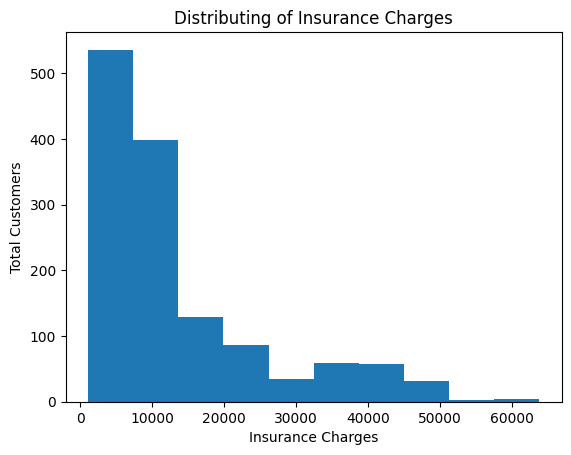

In [8]:
import matplotlib.pyplot as plt
plt.hist(df["charges"])
plt.title("Distributing of Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Total Customers")
plt.show()


In [9]:
df.groupby("smoker")["charges"].mean()

,charges
smoker,
no,8434.268298
yes,32050.231832


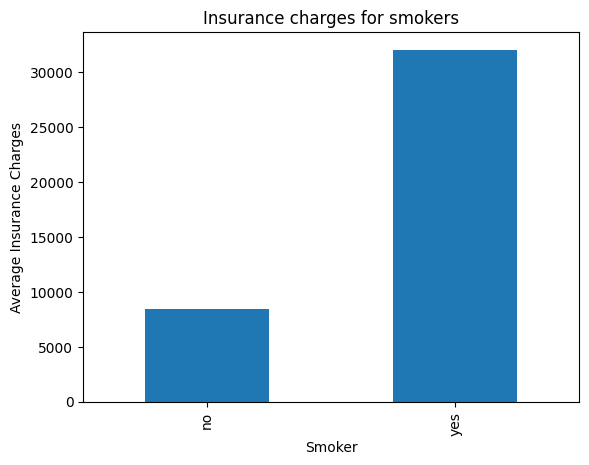

In [10]:
avg_charges = df.groupby("smoker")["charges"].mean()
avg_charges.plot(kind="bar")
plt.title("Insurance charges for smokers")
plt.xlabel("Smoker")
plt.ylabel("Average Insurance Charges")
plt.show()

In [11]:
x = df.drop(columns=["charges"])
y = df["charges"]

In [12]:
print(x.shape)
print(y.shape)

(1338, 6)
(1338,)


In [13]:
x.select_dtypes(include="object").columns

Index(['sex', 'smoker', 'region'], dtype='object')

In [14]:
x_encoded = pd.get_dummies(x, drop_first=True, dtype=int)

In [15]:
print(x_encoded.head())
print(x_encoded.shape)

   age     bmi  children  ...  region_northwest  region_southeast  region_southwest
0   19  27.900         0  ...                 0                 0                 1
1   18  33.770         1  ...                 0                 1                 0
2   28  33.000         3  ...                 0                 1                 0
3   33  22.705         0  ...                 1                 0                 0
4   32  28.880         0  ...                 1                 0                 0

[5 rows x 8 columns]
(1338, 8)


In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    x_encoded,
    y,
    test_size=0.2,
    random_state=42
)

In [17]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1070, 8)
(268, 8)
(1070,)
(268,)


In [18]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [19]:
model.fit(X_train, y_train)

LinearRegression()

In [20]:
y_pred=model.predict(X_test)

In [21]:
print(y_pred[:5])

[ 8969.55027444  7068.74744287 36858.41091155  9454.67850053
 26973.17345656]


In [22]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error== mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error:", mean_absolute_error)

Mean Absolute Error: <function mean_absolute_error at 0x7b3eb09c56c0>


In [24]:
print("Mean Absolute Error:", mean_absolute_error)

Mean Absolute Error: <function mean_absolute_error at 0x7b3eb09c56c0>


In [25]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

R2 Score: 0.7835929767120724


In [26]:
import pandas as pd

comparison = pd.DataFrame({
    "Actual Charges": y_test.values,
    "Predicted Charges": y_pred
})

print(comparison.head(10))

   Actual Charges  Predicted Charges
0      9095.06825        8969.550274
1      5272.17580        7068.747443
2     29330.98315       36858.410912
3      9301.89355        9454.678501
4     33750.29180       26973.173457
5      4536.25900       10864.113164
6      2117.33885         170.280841
7     14210.53595       16903.450287
8      3732.62510        1092.430936
9     10264.44210       11218.343184


In [29]:
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error:", mae)

Mean Absolute Error: 4181.19447375365
